In [2]:
import pandas as pd
import numpy as np

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from collections import Counter

## 6.1.1 ANN

In [3]:
folder = "Data Export Filter Method/"

X_train = pd.read_csv(folder + "X_train_selected.csv")
X_val = pd.read_csv(folder + "X_val_selected.csv")
X_test = pd.read_csv(folder + "X_test_selected.csv")


y_train = pd.read_csv(folder + "y_train.csv").values.ravel()
y_val = pd.read_csv(folder + "y_val.csv").values.ravel()
y_test = pd.read_csv(folder + "y_test.csv").values.ravel()


print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nClass distribution:")
print(Counter(y_train))

Train: (79980, 25)
Validation: (9997, 25)
Test: (9998, 25)

Class distribution:
Counter({np.int64(2): 63512, np.int64(3): 13689, np.int64(4): 2062, np.int64(1): 717})


## 6.1.1.1 Class Weighting

In [4]:

# N = len(y_train)


# C = len(np.unique(y_train))


# class_counts = Counter(y_train)


# class_weights = {}

# for cls, count in class_counts.items():
    
#     class_weights[cls] = N / (C * count)


# print("Class weights:")
# print(class_weights)

In [5]:
# sample_weights = np.array(
#     [
#         class_weights[label]
#         for label in y_train
#     ]
# )


# print(sample_weights[:10])

In [6]:
class_weights = {
    1: 10,
    2: 0.5,
    3: 2,
    4: 5
}

sample_weights = np.array(
    [class_weights[y] for y in y_train]
)

## 6.1.1.2 Hyper parameter Tuning

In [7]:
architectures = [

    (32,),

    (64,),

    (128,),

    (64,32),

    (128,64),

    (128,64,32),

    (256,128,64)

]

In [ ]:
results = []


for architecture in architectures:

    print("Training:", architecture)


    model = MLPClassifier(
        hidden_layer_sizes=architecture,
        activation="relu",
        solver="adam",
        batch_size=32,
        learning_rate_init=0.001,
        max_iter=200,
        random_state=42,
        early_stopping=True
    )


    model.fit(
        X_train,
        y_train,
        sample_weight=sample_weights
    )


    y_val_pred = model.predict(X_val)


    macro_f1 = f1_score(
        y_val,
        y_val_pred,
        average="macro"
    )


    acc = accuracy_score(
        y_val,
        y_val_pred
    )


    results.append(
        {
            "Architecture": architecture,
            "Validation Accuracy": acc,
            "Validation Macro F1": macro_f1
        }
    )

Training: (32,)
Training: (64,)
Training: (128,)
Training: (64, 32)
Training: (128, 64)
Training: (128, 64, 32)
Training: (256, 128, 64)


## 6.1.1.3 Selecting Model

In [9]:
results_df = pd.DataFrame(results)


results_df = results_df.sort_values(
    by="Validation Macro F1",
    ascending=False
)


results_df

,Architecture,Validation Accuracy,Validation Macro F1
5,"(128, 64, 32)",0.776233,0.489489
2,"(128,)",0.752026,0.485852
4,"(128, 64)",0.757927,0.485786
1,"(64,)",0.752626,0.482051
6,"(256, 128, 64)",0.750325,0.478571
3,"(64, 32)",0.749925,0.476153
0,"(32,)",0.744823,0.471768


In [10]:
best_architecture = results_df.iloc[0]["Architecture"]
final_model = MLPClassifier(
    hidden_layer_sizes=best_architecture,
    activation="relu",
    solver="adam",
    batch_size=32,
    learning_rate_init=0.001,
    max_iter=300,
    random_state=42
)


final_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print(best_architecture)

(128, 64, 32)


## 6.1.1.4 Model Analysis

In [11]:
y_test_pred = final_model.predict(X_test)


print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        y_test_pred
    )
)


print(
    "Test Macro F1:",
    f1_score(
        y_test,
        y_test_pred,
        average="macro"
    )
)


print(
    classification_report(
        y_test,
        y_test_pred
    )
)

Test Accuracy: 0.7588517703540708
Test Macro F1: 0.47289814876684777
              precision    recall  f1-score   support

           1       0.18      0.31      0.23        90
           2       0.93      0.77      0.84      7939
           3       0.52      0.80      0.63      1711
           4       0.13      0.33      0.18       258

    accuracy                           0.76      9998
   macro avg       0.44      0.55      0.47      9998
weighted avg       0.83      0.76      0.78      9998



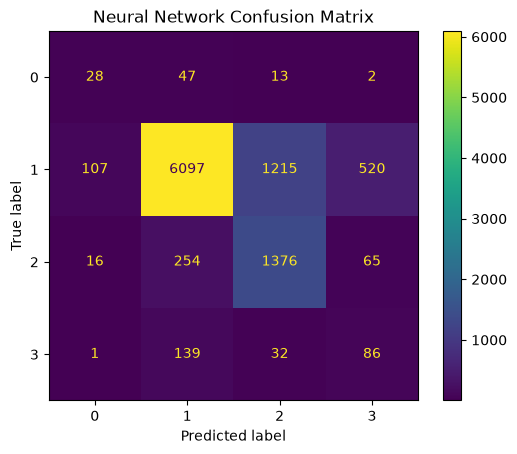

In [12]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay


cm = confusion_matrix(
    y_test,
    y_test_pred
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title(
    "Neural Network Confusion Matrix"
)

plt.show()